### Caricamento Dati

In [2]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

conn = sqlite3.connect("../data/flights.db")
flights = pd.read_sql("SELECT * FROM flights", conn)
flights.shape

(336776, 19)

### Ritardi per ora con mediana

In [3]:
dep = flights.dropna(subset=["dep_delay"]).copy()
dep["in_ritardo"] = dep["dep_delay"] > 15

per_ora = (
    dep.groupby("hour")
    .agg(
        voli=("dep_delay", "size"),
        media=("dep_delay", "mean"),
        mediana=("dep_delay", "median"),
        perc_ritardo=("in_ritardo", lambda s: 100 * s.mean()),
    )
    .round(2)
)
per_ora

,voli,media,mediana,perc_ritardo
hour,,,,
5,1944,0.69,-3.0,5.97
6,25526,1.64,-3.0,7.50
7,22532,1.91,-3.0,8.20
8,26800,4.13,-3.0,11.19
9,19985,4.58,-3.0,12.04
10,16418,6.50,-3.0,13.88
11,15737,7.19,-3.0,15.73
12,17793,8.61,-2.0,18.06
13,19527,11.44,-1.0,21.53


### Grafico

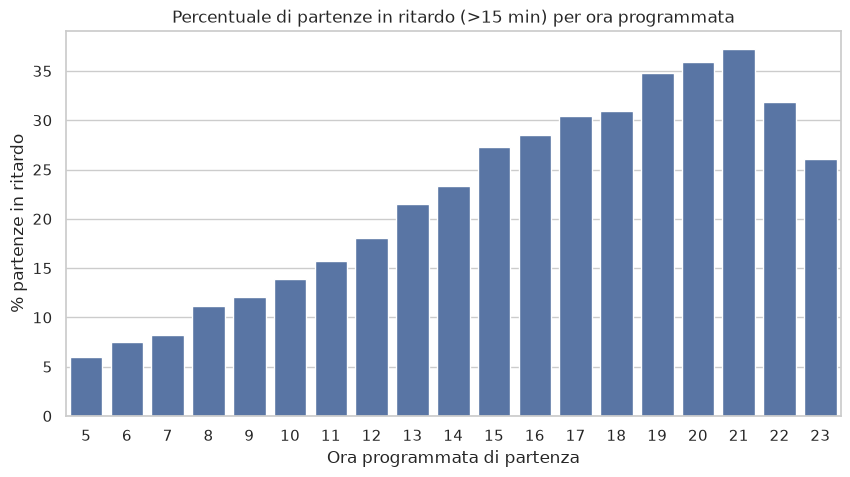

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=per_ora.index, y=per_ora["perc_ritardo"], color="#4C72B0", ax=ax)
ax.set_title("Percentuale di partenze in ritardo (>15 min) per ora programmata")
ax.set_xlabel("Ora programmata di partenza")
ax.set_ylabel("% partenze in ritardo")

Path("../reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("../reports/figures/ritardi_per_ora.png", dpi=150, bbox_inches="tight")
plt.show()

### Meteo

In [5]:
weather = pd.read_sql(
    "SELECT origin, year, month, day, hour, temp, wind_speed, precip, visib FROM weather",
    conn,
)

dep_w = dep.merge(weather, on=["origin", "year", "month", "day", "hour"], how="left")

# Quanti voli non hanno dato meteo associato
dep_w[["visib", "precip", "wind_speed"]].isna().mean().round(3)

visib         0.005
precip        0.005
wind_speed    0.005
dtype: float64

### Classi Meteo

In [6]:
def riepilogo(col):
    return (
        dep_w.groupby(col, observed=True)
        .agg(
            voli=("dep_delay", "size"),
            media=("dep_delay", "mean"),
            mediana=("dep_delay", "median"),
            perc_ritardo=("in_ritardo", lambda s: 100 * s.mean()),
        )
        .round(2)
    )

dep_w["classe_visibilita"] = pd.cut(
    dep_w["visib"], bins=[0, 1, 3, 6, 10], include_lowest=True
)
dep_w["pioggia"] = dep_w["precip"] > 0
dep_w["classe_vento"] = pd.cut(dep_w["wind_speed"], bins=[0, 10, 20, 30, 100], include_lowest=True)

for col in ["classe_visibilita", "pioggia", "classe_vento"]:
    display(riepilogo(col))

,voli,media,mediana,perc_ritardo
classe_visibilita,,,,
"(-0.001, 1.0]",4963,30.40,1.0,35.18
"(1.0, 3.0]",10426,23.15,1.0,32.73
"(3.0, 6.0]",12639,20.22,0.0,28.88
"(6.0, 10.0]",298965,11.65,-2.0,20.61


,voli,media,mediana,perc_ritardo
pioggia,,,,
False,307435,11.38,-2.0,20.34
True,21086,30.93,5.0,39.16


,voli,media,mediana,perc_ritardo
classe_vento,,,,
"(-0.001, 10.0]",146283,11.00,-2.0,19.55
"(10.0, 20.0]",160644,13.60,-1.0,22.70
"(20.0, 30.0]",19097,16.37,-1.0,26.40
"(30.0, 100.0]",891,28.04,2.0,33.11


### Classe meteo e classe oraria

In [7]:
dep_w["fascia"] = pd.cut(
    dep_w["hour"],
    bins=[0, 11, 16, 23],
    labels=["mattina (5-11)", "pomeriggio (12-16)", "sera (17-23)"],
)

controllo = (
    dep_w.groupby(["fascia", "pioggia"], observed=True)
    .agg(
        voli=("dep_delay", "size"),
        mediana=("dep_delay", "median"),
        perc_ritardo=("in_ritardo", lambda s: 100 * s.mean()),
    )
    .round(2)
)
controllo

voli  mediana  perc_ritardo
fascia             pioggia                               
mattina (5-11)     False    121060     -3.0         10.29
                   True       7882     -1.0         20.11
pomeriggio (12-16) False     96603     -1.0         22.51
                   True       7237     11.0         45.13
sera (17-23)       False     89772      1.0         31.54
                   True       5967     25.0         57.08

### Grafico

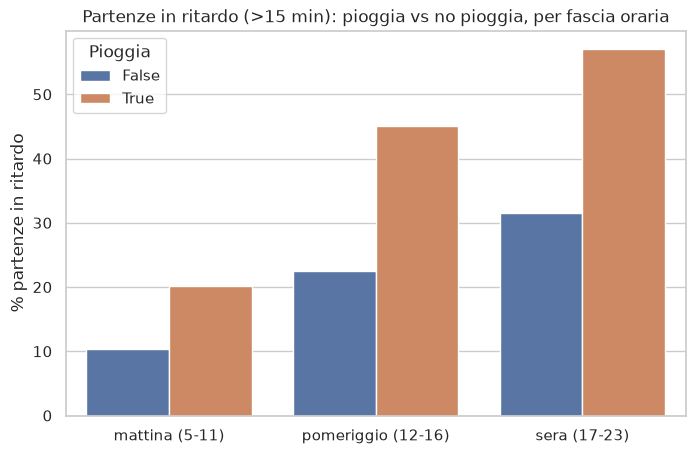

In [8]:
plot_df = controllo.reset_index()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=plot_df, x="fascia", y="perc_ritardo", hue="pioggia", ax=ax)
ax.set_title("Partenze in ritardo (>15 min): pioggia vs no pioggia, per fascia oraria")
ax.set_xlabel("")
ax.set_ylabel("% partenze in ritardo")
ax.legend(title="Pioggia")

fig.savefig("../reports/figures/ritardi_pioggia_per_fascia.png", dpi=150, bbox_inches="tight")
plt.show()

### Grafico compagnie

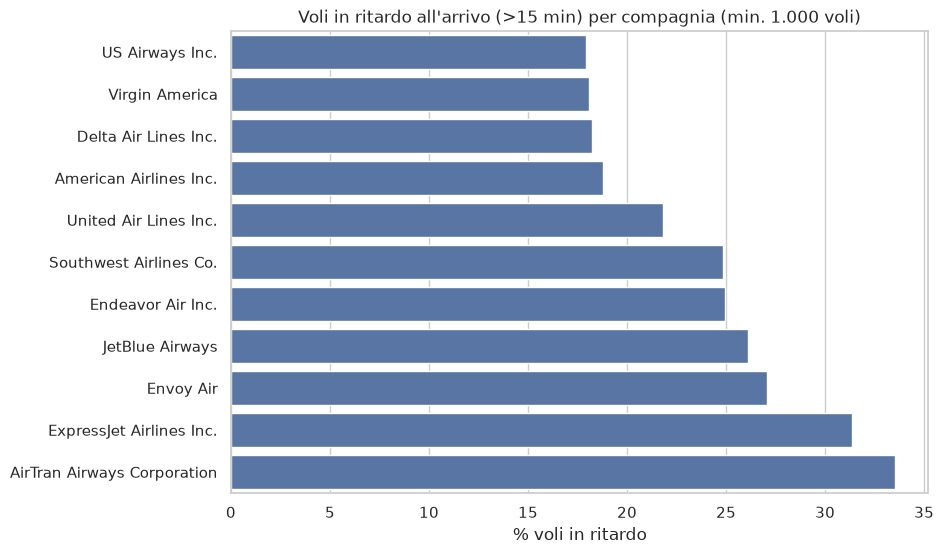

,carrier,voli,media,mediana,perc_ritardo,name
12,US,19831,2.13,-6.0,17.95,US Airways Inc.
13,VX,5116,1.76,-9.0,18.06,Virgin America
4,DL,47658,1.64,-8.0,18.23,Delta Air Lines Inc.
1,AA,31947,0.36,-9.0,18.79,American Airlines Inc.
11,UA,57782,3.56,-6.0,21.79,United Air Lines Inc.
14,WN,12044,9.65,-3.0,24.86,Southwest Airlines Co.
0,9E,17294,7.38,-7.0,24.92,Endeavor Air Inc.
3,B6,54049,9.46,-3.0,26.11,JetBlue Airways
9,MQ,25037,10.77,-1.0,27.07,Envoy Air
5,EV,51108,15.80,-1.0,31.36,ExpressJet Airlines Inc.


In [9]:
airlines = pd.read_sql("SELECT carrier, name FROM airlines", conn)

arr = flights.dropna(subset=["arr_delay"]).copy()
arr["in_ritardo"] = arr["arr_delay"] > 15

compagnie = (
    arr.groupby("carrier")
    .agg(
        voli=("arr_delay", "size"),
        media=("arr_delay", "mean"),
        mediana=("arr_delay", "median"),
        perc_ritardo=("in_ritardo", lambda s: 100 * s.mean()),
    )
    .round(2)
    .reset_index()
    .merge(airlines, on="carrier")
)
compagnie = compagnie[compagnie["voli"] >= 1000].sort_values("perc_ritardo")

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=compagnie, y="name", x="perc_ritardo", color="#4C72B0", ax=ax)
ax.set_title("Voli in ritardo all'arrivo (>15 min) per compagnia (min. 1.000 voli)")
ax.set_xlabel("% voli in ritardo")
ax.set_ylabel("")

fig.savefig("../reports/figures/ritardi_per_compagnia.png", dpi=150, bbox_inches="tight")
plt.show()
compagnie

### Grafico destinazioni

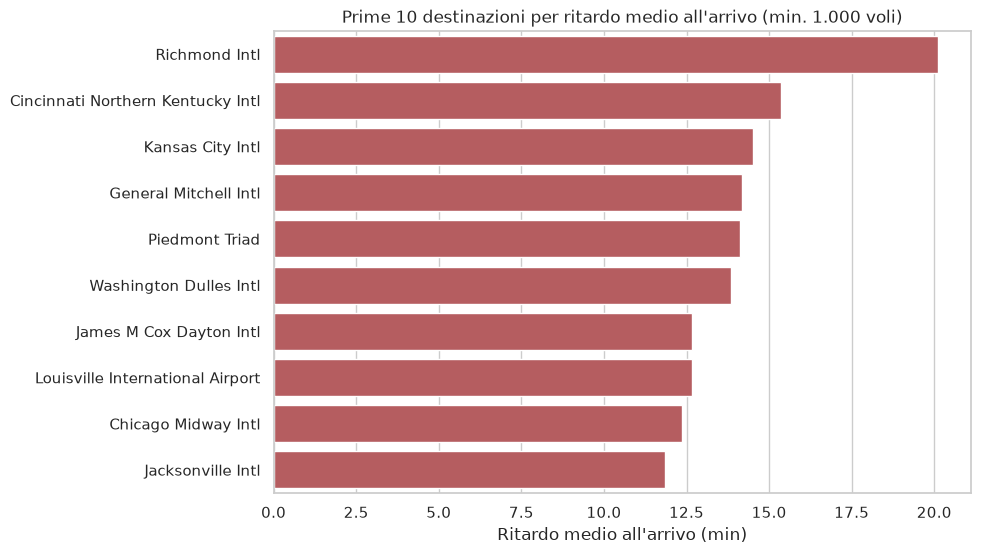

,dest,etichetta,voli,media,mediana
0,RIC,Richmond Intl,2346,20.11,1.0
1,CVG,Cincinnati Northern Kentucky Intl,3725,15.36,-3.0
2,MCI,Kansas City Intl,1885,14.51,0.0
3,MKE,General Mitchell Intl,2709,14.17,0.0
4,GSO,Piedmont Triad,1492,14.11,-2.0
5,IAD,Washington Dulles Intl,5383,13.86,-3.0
6,DAY,James M Cox Dayton Intl,1399,12.68,-3.0
7,SDF,Louisville International Airport,1104,12.67,-2.0
8,MDW,Chicago Midway Intl,4025,12.36,-1.0
9,JAX,Jacksonville Intl,2623,11.84,-2.0


In [10]:
airports = pd.read_sql("SELECT faa, name FROM airports", conn)

destinazioni = (
    arr.groupby("dest")
    .agg(voli=("arr_delay", "size"), media=("arr_delay", "mean"), mediana=("arr_delay", "median"))
    .round(2)
    .reset_index()
)
destinazioni = destinazioni[destinazioni["voli"] >= 1000]
top10 = destinazioni.nlargest(10, "media").merge(
    airports, left_on="dest", right_on="faa", how="left"
)
top10["etichetta"] = top10["name"].fillna(top10["dest"])

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=top10, y="etichetta", x="media", color="#C44E52", ax=ax)
ax.set_title("Prime 10 destinazioni per ritardo medio all'arrivo (min. 1.000 voli)")
ax.set_xlabel("Ritardo medio all'arrivo (min)")
ax.set_ylabel("")

fig.savefig("../reports/figures/ritardi_per_destinazione.png", dpi=150, bbox_inches="tight")
plt.show()
top10[["dest", "etichetta", "voli", "media", "mediana"]]

In [11]:
import sys
sys.path.append("..")

from src.analysis import load_table, summarize_delays

flights = load_table("flights")
summarize_delays(flights, by="hour", delay_col="dep_delay")

,voli,media,mediana,perc_ritardo
hour,,,,
5,1944,0.69,-3.0,5.97
6,25526,1.64,-3.0,7.50
7,22532,1.91,-3.0,8.20
8,26800,4.13,-3.0,11.19
9,19985,4.58,-3.0,12.04
10,16418,6.50,-3.0,13.88
11,15737,7.19,-3.0,15.73
12,17793,8.61,-2.0,18.06
13,19527,11.44,-1.0,21.53
